# 估计误差的偏差–方差分解

09 篇实验 A 只报告了 RMSE：在 t(4) 下，高斯插件的 ES **水平**误差更大（T = 1000 时 12.3% 对 7.8%），**形状**（两个组合 ES 之比）误差更小（4.6% 对 6.3%）。
本 notebook 把均方误差拆成
$$\mathrm{MSE}(\hat\theta)=\underbrace{(\mathbb E\hat\theta-\theta)^2}_{\text{偏差}^2}+\underbrace{\mathrm{Var}(\hat\theta)}_{\text{方差}},$$
回答三个问题：

1. 分布误设造成的偏差，在比值中是否消失？
2. 高斯插件在形状上的有限样本优势，来自更小的偏差，还是更小的方差？
3. 真实分布不是椭圆分布时，两种方法的优劣怎样随样本量变化？

与实验 A 相比，新增的是：自由度 ν ∈ {3, 4, 5, 8, 15}、三个置信水平、每格 5000 次重复，以及**理论基准**——
每个估计量的渐近偏差与渐近方差，由影响函数在 1000 万天样本上算出，用来判断模拟结果是否已进入渐近区间。理论依据见 [theory_es_ratio.md](theory_es_ratio.md)。

误差都用相对误差 $\hat\theta/\theta-1$ 表示（%）。第 5 节加入第三种比值估计量：只估计形状的 Tyler M 估计量。

## 0 · 环境

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .3,
    "axes.spines.top": False, "axes.spines.right": False, "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})
C_GAUSS, C_HS, C_REF = "#2a78d6", "#eb6834", "#8a8984"      # 与 09 篇主 notebook 相同的配色

RERUN = False                                   # True：忽略缓存重跑（约 3 分钟）
QUICK = os.environ.get("S09_QUICK") == "1"      # 冒烟测试
RES = Path("results")
RES.mkdir(exist_ok=True)


def cached(name, fn):
    path = RES / f"{name}{'_quick' if QUICK else ''}.csv.gz"
    if path.exists() and not RERUN:
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False, float_format="%.6g")     # 6 位有效数字，控制文件大小
    return df

## 1 · 数据生成过程与固定组合

资产宇宙、相关结构与崩盘混合和 09 篇主 notebook 完全相同（这里复制定义，不依赖主 notebook）；t 分布推广到一般的 ν，全部缩放到单位方差，七个 DGP 的协方差都等于 Σ。

被估计的量固定在两个组合上：$w^\*_{\min}$（真实 Σ 下的最小方差组合，单资产上限 40%）与等权组合 EW。
- **水平**：$\mathrm{ES}_q(L_{\mathrm{EW}})$。
- **形状**：$\theta=\mathrm{ES}_q(L_{w^\*_{\min}})/\mathrm{ES}_q(L_{\mathrm{EW}})$。

椭圆族中 $w^\*_{\min}$ 也是 min ES 的最优解，与实验 A 相同；崩盘混合下实验 A 用的是该分布自己的 min ES 最优解，这里统一用 $w^\*_{\min}$，所以崩盘混合的数字与实验 A 不可直接对比。

两种估计量：
- **高斯插件**：$\hat{\mathrm{ES}}=k^N_q\sqrt{w^\top\hat\Sigma w}$，$\hat\Sigma$ 为样本协方差；比值即 $\sqrt{w_1^\top\hat\Sigma w_1/w_2^\top\hat\Sigma w_2}$，与 $q$ 无关。
- **历史法（HS）**：样本 ES，最差 $\lceil(1-q)T\rceil$ 个观测的平均损失。

In [2]:
import numpy as np, pandas as pd
from numpy.linalg import cholesky
from scipy.optimize import minimize
from scipy.stats import norm, t as student_t

ASSETS = ["沪深300", "中证500", "标普500", "国债", "黄金", "原油"]
N_ASSETS = 6
ANN_VOL = np.array([0.25, 0.28, 0.18, 0.03, 0.15, 0.32])
DAYS = 244
SIG = ANN_VOL / np.sqrt(DAYS)
CORR = np.array([
    [1.00, 0.85, 0.25, -0.10, 0.05, 0.20],
    [0.85, 1.00, 0.20, -0.10, 0.05, 0.20],
    [0.25, 0.20, 1.00, -0.20, 0.05, 0.30],
    [-0.10, -0.10, -0.20, 1.00, 0.15, -0.10],
    [0.05, 0.05, 0.05, 0.15, 1.00, 0.25],
    [0.20, 0.20, 0.30, -0.10, 0.25, 1.00],
])
SIGMA = np.outer(SIG, SIG) * CORR
L_CORR = cholesky(CORR)
UPPER = 0.40
CRASH_DIR = np.array([-3.0, -3.0, -2.5, 1.0, 0.5, -2.5])
_EK, _EK2 = 2.0, 5.0
P_CRASH = 0.01

def _crash_transform(p):
    m = p * _EK * CRASH_DIR
    cov = CORR + p * _EK2 * np.outer(CRASH_DIR, CRASH_DIR) - np.outer(m, m)
    return m, np.linalg.inv(cholesky(cov)).T @ L_CORR.T
_CRASH_M, _CRASH_A = _crash_transform(P_CRASH)

NUS = [3, 4, 5, 8, 15]
DGPS = ["高斯"] + [f"t({v})" for v in NUS] + ["崩盘混合"]
NU_OF = {f"t({v})": v for v in NUS}
QS = [0.95, 0.975, 0.99]

def draw_innov(kind, n, rng):
    z = rng.standard_normal((n, N_ASSETS)) @ L_CORR.T
    if kind == "高斯":
        return z
    if kind in NU_OF:
        nu = NU_OF[kind]
        return z * np.sqrt((nu - 2) / rng.chisquare(nu, n))[:, None]
    if kind == "崩盘混合":
        k = (rng.random(n) < P_CRASH) * (1 + rng.exponential(1.0, n))
        return (z + k[:, None] * CRASH_DIR - _CRASH_M) @ _CRASH_A
    raise ValueError(kind)

def k_es(kind, q):
    """单位方差下 ES 的常数 k_q；崩盘混合不是椭圆分布，返回 None。"""
    if kind == "高斯":
        return norm.pdf(norm.ppf(q)) / (1 - q)
    if kind in NU_OF:
        nu = NU_OF[kind]; tq = student_t.ppf(q, nu)
        return np.sqrt((nu - 2) / nu) * student_t.pdf(tq, nu) / (1 - q) * (nu + tq ** 2) / (nu - 1)
    return None

def es_sample(x, q, axis=0):
    """样本 ES（损失为正）：沿 axis 取最差 ⌈(1−q)n⌉ 个收益的平均损失。"""
    n = x.shape[axis]
    k = max(int(np.ceil((1 - q) * n)), 1)
    part = np.partition(x, k - 1, axis=axis)
    return -np.take(part, np.arange(k), axis=axis).mean(axis=axis)

# 固定组合：真实 Σ 下的最小方差（单资产上限 40%，不做空）与等权。
def min_var_capped(S, upper=UPPER):
    n = len(S)
    res = minimize(lambda w: w @ S @ w, np.full(n, 1 / n), jac=lambda w: 2 * S @ w,
                   bounds=[(0, upper)] * n, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   method="SLSQP", options={"ftol": 1e-15, "maxiter": 500})
    return res.x

W_MIN = min_var_capped(SIGMA)
W_EW = np.full(N_ASSETS, 1 / N_ASSETS)
W_PAIR = np.column_stack([W_MIN, W_EW])            # 列：w*min、EW
SD = np.sqrt(np.einsum("ij,jk,ki->i", W_PAIR.T, SIGMA, W_PAIR))   # σ_w
RHO = (W_MIN @ SIGMA @ W_EW) / (SD[0] * SD[1])

print("w*min =", dict(zip(ASSETS, W_MIN.round(4))))
print(f"σ_w*min / σ_EW = {SD[0] / SD[1]:.4f}，ρ(w*min, EW) = {RHO:.4f}")

w*min = {'沪深300': np.float64(0.0606), '中证500': np.float64(0.0208), '标普500': np.float64(0.2095), '国债': np.float64(0.4), '黄金': np.float64(0.3091), '原油': np.float64(0.0)}
σ_w*min / σ_EW = 0.5352，ρ(w*min, EW) = 0.7429


## 2 · 理论基准：渐近偏差与渐近方差

每个估计量的相对误差有一阶展开
$\hat\theta_T/\theta-1=\beta+\frac1T\sum_t\mathrm{IF}(X_t)+o_p(T^{-1/2})$，
其中 $\beta$ 是渐近偏差（估计量的概率极限与真值之差），$\mathrm{IF}$ 是影响函数。$\mathrm{Var}(\mathrm{IF})<\infty$ 时 $T\cdot\mathrm{Var}\to\mathrm{Var}(\mathrm{IF})$。

| 估计量 | 渐近偏差 β | 影响函数（相对误差） |
|---|---|---|
| 高斯 · 水平 | $k^N_q\sigma_{\mathrm{EW}}/\mathrm{ES}-1$ | $\tfrac12(L^2/\sigma^2-1)$ |
| 高斯 · 比值 | $(\sigma_1/\sigma_2)/\theta-1$ | $\tfrac12(L_1^2/\sigma_1^2-L_2^2/\sigma_2^2)$ |
| HS · 水平 | 0 | $[v_q+(L-v_q)_+/(1-q)-\mathrm{ES}]/\mathrm{ES}$ |
| HS · 比值 | 0 | 两个组合上述影响函数之差 |

椭圆族中高斯比值的 β = 0（命题 1），且渐近方差有闭式：$T\cdot\mathrm{Var}\to(1-\rho^2)\,(\nu-2)/(\nu-4)$（高斯时因子为 1）；
**ν ≤ 4 时四阶矩不存在，影响函数方差无穷，没有 √T 的正态极限**——这时 $T\cdot\mathrm{Var}$ 应随 T 增大。
HS 只需要二阶矩，对所有 ν > 2 都是 √T 收敛。崩盘混合的各项在 1000 万天样本上数值计算。

In [3]:
# ── 总体真值与渐近方差（影响函数在大样本上的方差）──────────────────────────────
def big_losses(kind, n=10_000_000, seed=2024, chunk=1_000_000):
    rng = np.random.default_rng(seed)
    out = [(-(draw_innov(kind, chunk, rng) * SIG) @ W_PAIR) for _ in range(n // chunk)]
    return np.vstack(out)                           # (n, 2) 两个组合的损失

def theory(kind, L):
    """返回该 DGP 每个 q 的真值、渐近偏差与 n·Var（相对误差尺度）。"""
    rows = []
    l2 = (L / SD) ** 2
    # 高斯插件（样本协方差）：水平的影响函数 ½(L²/σ² − 1)；比值的影响函数 ½(L1²/σ1² − L2²/σ2²)
    nu = NU_OF.get(kind, np.inf)
    if kind == "崩盘混合":
        av_g_lvl = np.var(0.5 * l2[:, 1]); av_g_rat = np.var(0.5 * (l2[:, 0] - l2[:, 1]))
    elif nu > 4:
        kap = 0 if np.isinf(nu) else 2 / (nu - 4)
        av_g_lvl = (2 + 3 * kap) / 4; av_g_rat = (1 - RHO ** 2) * (1 + kap)
    else:
        av_g_lvl = av_g_rat = np.inf               # 四阶矩不存在：没有 √n 的正态极限
    for q in QS:
        k = k_es(kind, q)
        v = np.quantile(L, q, axis=0)
        ifs = v + np.maximum(L - v, 0) / (1 - q)    # ES 的影响函数（差一个常数）
        es_mc = ifs.mean(axis=0)
        es_true = k * SD if k is not None else es_mc
        rel = ifs / es_true
        theta = es_true[0] / es_true[1]
        k_g = k_es("高斯", q)
        rows.append(dict(
            dgp=kind, q=q, theta=theta,
            es_ew=es_true[1],
            # 高斯插件的渐近相对偏差：水平 = k_N σ / ES − 1；比值 = (σ1/σ2) / θ − 1
            abias_g_lvl=k_g * SD[1] / es_true[1] - 1,
            abias_g_rat=(SD[0] / SD[1]) / theta - 1,
            avar_g_lvl=av_g_lvl * (k_g * SD[1] / es_true[1]) ** 2,
            avar_g_rat=av_g_rat * ((SD[0] / SD[1]) / theta) ** 2,
            avar_hs_lvl=np.var(rel[:, 1]),
            avar_hs_rat=np.var(rel[:, 0] - rel[:, 1]),
            es_mc_check=es_mc[1] / es_true[1] - 1,
        ))
    return rows

THEORY = cached("expD_theory", lambda: pd.DataFrame([r for k in DGPS for r in theory(k, big_losses(k))]))
THEORY.set_index(["dgp", "q"]).loc[DGPS].style.format("{:.4f}")

## 3 · 模拟

七个 DGP × T ∈ {125, 250, 500, 1000, 2000, 4000} × 5000 次重复；同一批样本同时算三个置信水平。
真值：椭圆族用解析式，崩盘混合用上面的 1000 万天样本。

In [4]:
# ── 模拟 ──────────────────────────────────────────────────────────────────
def run_cell(kind, T, reps, seed, tru, batch=100):
    """tru：{q: (θ, ES_EW)}。返回每次重复的相对误差。"""
    rng = np.random.default_rng(seed)
    out = []
    kg = {q: k_es("高斯", q) for q in QS}
    for b0 in range(0, reps, batch):
        B = min(batch, reps - b0)
        R = draw_innov(kind, B * T, rng).reshape(B, T, N_ASSETS) * SIG
        P = R @ W_PAIR                                # (B, T, 2) 两个组合的收益
        Pc = P - P.mean(axis=1, keepdims=True)
        var = (Pc ** 2).sum(axis=1) / (T - 1)         # 与 np.cov 一致：样本协方差在 w 上的二次型
        sd = np.sqrt(var)
        rat_g = sd[:, 0] / sd[:, 1]
        rec = {"dgp": kind, "T": T, "rep": np.arange(b0, b0 + B)}
        for q in QS:
            th, es_ew = tru[q]
            es_hs = es_sample(P, q, axis=1)           # (B, 2)
            tag = f"{int(round(q * 1000))}"
            rec[f"g_lvl_{tag}"] = kg[q] * sd[:, 1] / es_ew - 1
            rec[f"hs_lvl_{tag}"] = es_hs[:, 1] / es_ew - 1
            rec[f"g_rat_{tag}"] = rat_g / th - 1
            rec[f"hs_rat_{tag}"] = es_hs[:, 0] / es_hs[:, 1] / th - 1
        out.append(pd.DataFrame(rec))
    return pd.concat(out, ignore_index=True)


T_GRID = [125, 1000] if QUICK else [125, 250, 500, 1000, 2000, 4000]
N_REPS = 200 if QUICK else 5000


def run_all():
    out = []
    for i, kind in enumerate(DGPS):
        th = THEORY[THEORY.dgp == kind]
        tru = {r.q: (r.theta, r.es_ew) for r in th.itertuples()}
        for j, T in enumerate(T_GRID):
            out.append(run_cell(kind, T, N_REPS, [2026, i, j], tru))
    return pd.concat(out, ignore_index=True)


SIM = cached("expD_biasvar", run_all)
print(len(SIM), "行；", SIM.groupby(["dgp", "T"]).size().min(), "次重复 / 格")

210000 行； 5000 次重复 / 格


In [5]:
# 汇总：每格每个估计量的偏差、标准差、RMSE、偏差² 占 MSE 的比例，以及蒙特卡洛标准误
EST = {"g_lvl": "高斯·水平", "hs_lvl": "HS·水平", "g_rat": "高斯·比值", "hs_rat": "HS·比值"}


def summarise(sim):
    rows = []
    for (kind, T), g in sim.groupby(["dgp", "T"], sort=False):
        for q in QS:
            tag = f"{int(round(q * 1000))}"
            for key, lab in EST.items():
                e = g[f"{key}_{tag}"].to_numpy()
                b, v = e.mean(), e.var(ddof=1)
                rows.append(dict(dgp=kind, T=T, q=q, est=lab, bias=b * 100, sd=np.sqrt(v) * 100,
                                 rmse=np.sqrt((e ** 2).mean()) * 100, bias2_share=b ** 2 / (b ** 2 + v),
                                 se_bias=np.sqrt(v / len(e)) * 100, Tvar=T * v,
                                 mae_med=np.median(np.abs(e)) * 100))
    return pd.DataFrame(rows)


SUM = summarise(SIM)
pick = lambda **kw: SUM.loc[np.logical_and.reduce([SUM[k] == v for k, v in kw.items()])]

## 4 · 结果

### 4.1 t(4)、q = 0.95：与实验 A 对照

实验 A 每格 500 次重复。下面同时列出从实验 A 原始结果（`results/expA.csv.gz`）重新算出的偏差与标准差。

In [6]:
A = pd.read_csv(RES / "expA.csv.gz")
A = A[(A.dgp == "t(4)") & A.rule.isin(["est@EW", "est@ratio"])]
ga = A.groupby(["T", "rule"])
expA = pd.DataFrame({
    ("实验A", "高斯 偏差"): ga.err_gauss.mean(), ("实验A", "高斯 sd"): ga.err_gauss.std(),
    ("实验A", "HS 偏差"): ga.err_hs.mean(), ("实验A", "HS sd"): ga.err_hs.std(),
}) * 100
expA = expA.rename(index={"est@EW": "水平", "est@ratio": "比值"}, level=1)

t4 = pick(dgp="t(4)", q=0.95).copy()
t4["目标"] = t4.est.str.split("·").str[1]
t4["方法"] = t4.est.str.split("·").str[0]
new = t4.pivot_table(index=["T", "目标"], columns="方法", values=["bias", "sd", "rmse", "bias2_share"])
new.columns = [f"{m} {s}" for s, m in new.columns]
new = new[[f"{m} {s}" for m in ["高斯", "HS"] for s in ["bias", "sd", "rmse", "bias2_share"]]]
new.columns = pd.MultiIndex.from_tuples([("本次（5000 次）", c) for c in new.columns])
tab1 = new.join(expA)
tab1.style.format("{:.2f}")

### 4.2 形状误差：偏差还是方差？（q = 0.95）

偏差² 占 MSE 的比例。

In [7]:
rat = pick(q=0.95)[lambda d: d.est.str.endswith("比值")]
tab2 = rat.pivot_table(index="dgp", columns=["est", "T"], values="bias2_share").loc[DGPS]
tab2.style.format("{:.3f}")

In [8]:
tab2b = rat.pivot_table(index="dgp", columns=["est", "T"], values="bias").loc[DGPS]
print("比值的偏差（%）")
tab2b.style.format("{:+.2f}")

比值的偏差（%）


### 4.3 方差的收敛速度：T · Var 与理论值

若估计量是 √T 收敛的，T · Var 应趋于理论渐近方差（虚线）。高斯插件在 t(3)、t(4) 下没有有限的渐近方差，T · Var 应随 T 上升。

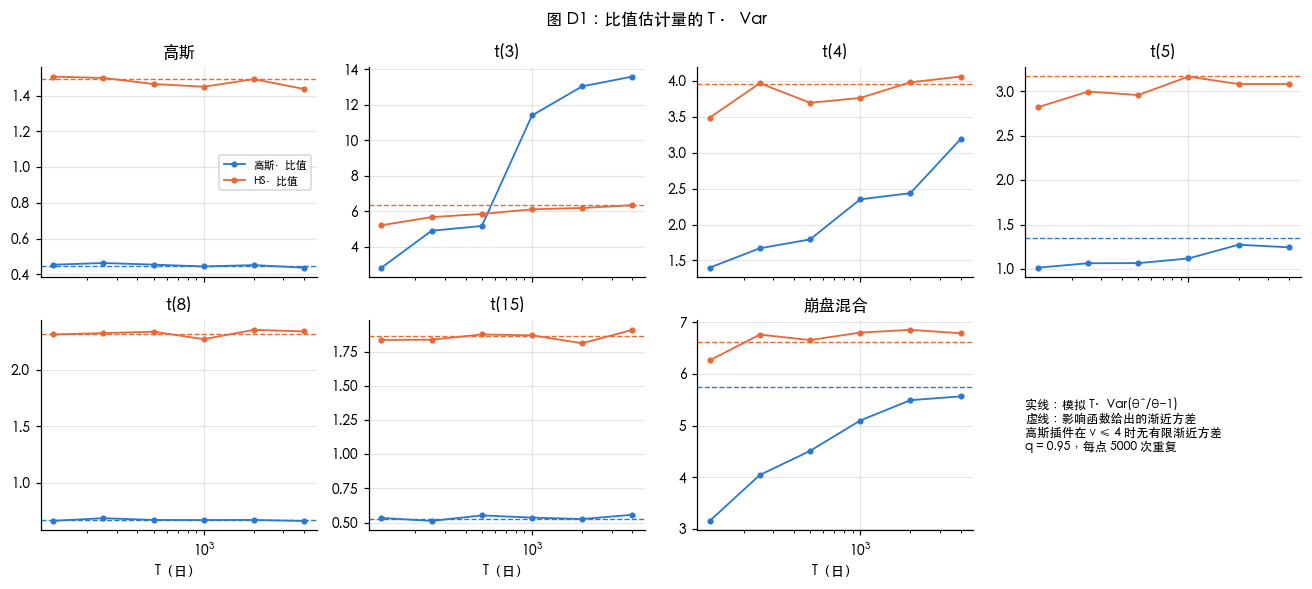

In [9]:
TH = THEORY.set_index(["dgp", "q"])
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4), sharex=True)
for ax, kind in zip(axes.flat, DGPS):
    for key, c in [("高斯·比值", C_GAUSS), ("HS·比值", C_HS)]:
        d = pick(dgp=kind, q=0.95, est=key)
        ax.plot(d["T"], d["Tvar"], "o-", color=c, ms=3, lw=1.2, label=key)
        av = TH.loc[(kind, 0.95), "avar_g_rat" if key.startswith("高斯") else "avar_hs_rat"]
        if np.isfinite(av):
            ax.axhline(av, color=c, ls="--", lw=.9)
    ax.set_xscale("log")
    ax.set_title(kind)
axes.flat[0].legend(fontsize=7)
axes.flat[-1].axis("off")
axes.flat[-1].text(0, .5, "实线：模拟 T·Var(θ̂/θ−1)\n虚线：影响函数给出的渐近方差\n高斯插件在 ν ≤ 4 时无有限渐近方差\nq = 0.95，每点 5000 次重复", fontsize=8, va="center", transform=axes.flat[-1].transAxes)
for ax in axes[1]:
    ax.set_xlabel("T（日）")
fig.suptitle("图 D1：比值估计量的 T · Var")
fig.tight_layout()
plt.show()

In [10]:
# ν ≤ 4 时高斯比值的方差衰减速度：log Var 对 log T 的斜率（√T 收敛对应 −1）。
# 理论猜想（见理论附注后续部分）：2 < ν < 4 时误差为 T^{−(1−2/ν)} 量级，即方差斜率 −2(1−2/ν)；ν = 4 为 −1 加对数修正。
slopes = []
for kind in DGPS:
    for key in ["高斯·比值", "HS·比值"]:
        d = pick(dgp=kind, q=0.95, est=key)
        d = d[d["T"] >= 500]
        b = np.polyfit(np.log(d["T"]), np.log(d["sd"] ** 2), 1)[0]
        slopes.append(dict(dgp=kind, est=key, 斜率_T500起=b))
slope_tab = pd.DataFrame(slopes).pivot(index="dgp", columns="est", values="斜率_T500起").loc[DGPS]
slope_tab["猜想（高斯）"] = [-2 * (1 - 2 / NU_OF[k]) if k in NU_OF and NU_OF[k] < 4 else -1.0 for k in DGPS]
slope_tab.style.format("{:.2f}")

est,HS·比值,高斯·比值,猜想（高斯）
dgp,,,
高斯,-1.00,-1.01,-1.00
t(3),-0.96,-0.56,-0.67
t(4),-0.95,-0.75,-1.00
t(5),-0.99,-0.91,-1.00
t(8),-0.99,-1.01,-1.00
t(15),-1.00,-1.00,-1.00
崩盘混合,-0.99,-0.90,-1.00


### 4.4 置信水平的影响（T = 1000）

高斯比值不依赖 q（椭圆族中真值也不依赖 q）；HS 的尾部观测数随 q 提高而减少。

In [11]:
tab4 = pick(T=1000)[lambda d: d.est.str.endswith("比值")].pivot_table(index="dgp", columns=["est", "q"], values="rmse").loc[DGPS]
tab4.style.format("{:.2f}")

### 4.5 非椭圆分布：偏差与方差的交叉点

崩盘混合下，高斯比值有不随样本消失的偏差 β，HS 没有偏差但方差更大。忽略 O(1/T) 的有限样本偏差，
$\mathrm{MSE}_G\approx\beta^2+V_G/T$，$\mathrm{MSE}_{HS}\approx V_{HS}/T$，所以 HS 胜出的样本量约为
$$T^\*\approx\frac{V_{HS}-V_G}{\beta^2}.$$

In [12]:
rows = []
for q in QS:
    th = TH.loc[("崩盘混合", q)]
    tstar = (th.avar_hs_rat - th.avar_g_rat) / th.abias_g_rat ** 2
    d = pick(dgp="崩盘混合", q=q).pivot_table(index="T", columns="est", values="rmse")
    diff = d["高斯·比值"] - d["HS·比值"]
    sim_cross = next((T for T, x in diff.items() if x > 0), np.nan)
    rows.append(dict(q=q, 渐近偏差_pct=th.abias_g_rat * 100, V_G=th.avar_g_rat, V_HS=th.avar_hs_rat,
                     T星_理论=tstar, 模拟中HS首次胜出的T=sim_cross))
tab5 = pd.DataFrame(rows).set_index("q")
tab5.style.format("{:.2f}")

,渐近偏差_pct,V_G,V_HS,T星_理论,模拟中HS首次胜出的T
q,,,,,
0.950000,8.90,5.74,6.61,110.14,250.00
0.975000,25.10,7.57,10.96,53.85,125.00
0.990000,58.67,12.18,14.40,6.43,125.00


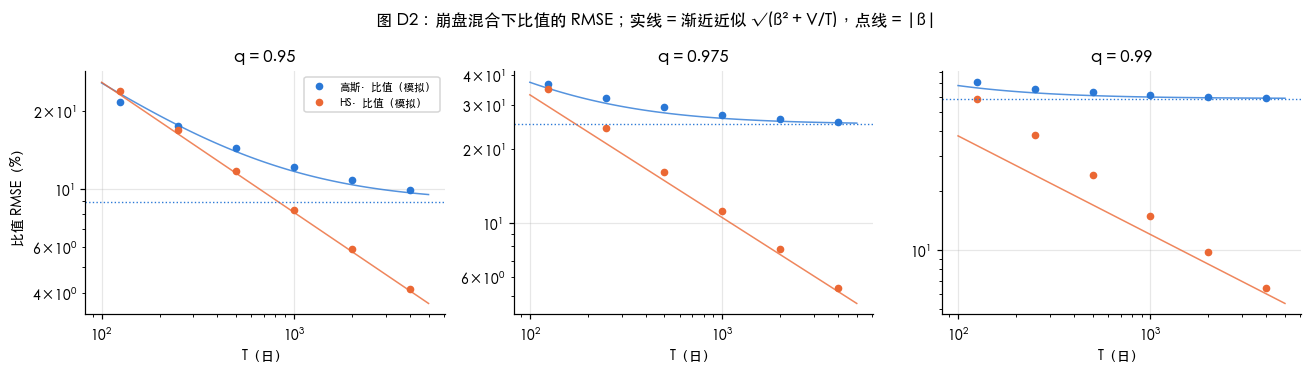

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
T_fine = np.geomspace(100, 5000, 100)
for ax, q in zip(axes, QS):
    th = TH.loc[("崩盘混合", q)]
    for key, c in [("高斯·比值", C_GAUSS), ("HS·比值", C_HS)]:
        d = pick(dgp="崩盘混合", q=q, est=key)
        ax.plot(d["T"], d["rmse"], "o", color=c, ms=4, label=f"{key}（模拟）")
        pred = np.sqrt(th.abias_g_rat ** 2 + th.avar_g_rat / T_fine) if key.startswith("高斯") else np.sqrt(th.avar_hs_rat / T_fine)
        ax.plot(T_fine, pred * 100, "-", color=c, lw=1, alpha=.8)
    ax.axhline(abs(th.abias_g_rat) * 100, color=C_GAUSS, ls=":", lw=.9)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"q = {q}"); ax.set_xlabel("T（日）")
axes[0].set_ylabel("比值 RMSE（%）")
axes[0].legend(fontsize=7)
fig.suptitle("图 D2：崩盘混合下比值的 RMSE；实线 = 渐近近似 √(β² + V/T)，点线 = |β|")
fig.tight_layout()
plt.show()

### 4.6 水平误差：同样的分解

高斯插件在水平上的误差几乎全是偏差（常数 $k^N_q/k_q-1$），HS 几乎全是方差。

In [14]:
lvl = pick(T=1000)[lambda d: d.est.str.endswith("水平")]
tab6 = lvl.pivot_table(index="dgp", columns=["est", "q"], values=["bias", "rmse"]).loc[DGPS]
tab6.style.format("{:+.2f}")

## 5 · Tyler 形状估计量

ES 比值只依赖离散矩阵的**形状**（[理论附注](theory_es_ratio.md) 命题 1(c)），所以不必估计完整的协方差，可以直接估计形状。
Tyler（1987）的 M 估计量是下面不动点方程的解（取 tr V = d 归一化）：
$$\hat V=\frac dT\sum_{t=1}^T\frac{X_tX_t^\top}{X_t^\top\hat V^{-1}X_t}.$$
它只用到观测的**方向** $X_t/\|X_t\|$，与径向分布无关。插件比值为 $\hat\theta_{\mathrm{Tyler}}=\sqrt{w_1^\top\hat Vw_1/w_2^\top\hat Vw_2}$。
这里用样本均值中心化（高斯插件也是如此），不使用「均值已知为 0」的信息。

**理论预测**（椭圆族，d = 6）：
- Tyler 比值相合，且不需要任何矩条件，所以 ν ≤ 4 时仍是 √T 收敛。
- 形状估计的渐近协方差是正态理论形状协方差的 (d+2)/d 倍，且对所有椭圆分布相同（Tyler 1987）。代入 Delta 方法，比值相对误差的渐近方差为
  $V_{\mathrm{Tyler}}=\frac{d+2}{d}(1-\rho^2)$，不依赖 ν；样本协方差插件为 $V_G=(1-\rho^2)\frac{\nu-2}{\nu-4}$。
- 两者之比：$V_{\mathrm{Tyler}}<V_G\iff\nu<d+4$。本篇 d = 6，所以 **ν < 10 时 Tyler 渐近更有效**，t(15) 与高斯时样本协方差更有效（正态下 Tyler 的效率为 d/(d+2) = 75%）。
  这一比较是我们自己的推导，下面用模拟检验。
- 位置用样本均值估计：椭圆对称时它对形状的一阶误差没有贡献，模拟同样检验这一点。

非椭圆分布下 Tyler 的极限一般不等于 Σ 的形状。崩盘混合的极限比值在 200 万天样本上计算。

In [15]:
# ── Tyler 形状估计量 ─────────────────────────────────────────────────────────
def tyler_shape(X, tol=1e-9, max_iter=500):
    """批量 Tyler M 估计量。X：(B, T, d)，已中心化。返回 (B, d, d)，tr = d，以及迭代次数。
    不动点迭代 V ← (d/T) Σ x xᵀ / (xᵀ V⁻¹ x)，每步归一化 tr(V) = d（Tyler 1987；Kent & Tyler 1988 证明了收敛）。"""
    B, T, d = X.shape
    V = np.broadcast_to(np.eye(d), (B, d, d)).copy()
    for it in range(1, max_iter + 1):
        q = np.einsum("bti,bij,btj->bt", X, np.linalg.inv(V), X)
        Vn = (d / T) * np.einsum("bti,btj->bij", X / q[..., None], X)
        Vn *= d / np.trace(Vn, axis1=1, axis2=2)[:, None, None]
        if np.max(np.abs(Vn - V)) < tol:
            return Vn, it
        V = Vn
    return V, max_iter


def ratio_from_shape(V):
    """形状矩阵 V（可带批次维）给出的 ES 比值 √(w1ᵀVw1 / w2ᵀVw2)。"""
    a = np.einsum("i,...ij,j->...", W_MIN, V, W_MIN)
    b = np.einsum("i,...ij,j->...", W_EW, V, W_EW)
    return np.sqrt(a / b)


def tyler_theory(kind, n=2_000_000, seed=2025):
    """Tyler 比值的概率极限（大样本上的 Tyler 估计）与椭圆族的渐近方差 (d+2)/d·(1−ρ²)。"""
    if kind in NU_OF or kind == "高斯":
        lim = SD[0] / SD[1]                       # 椭圆族：Tyler 的极限与 Σ 的形状相同
        avar_rel = (N_ASSETS + 2) / N_ASSETS * (1 - RHO ** 2)
    else:
        Z = draw_innov(kind, n, np.random.default_rng(seed)) * SIG
        V, _ = tyler_shape(Z[None], tol=1e-12)
        lim = ratio_from_shape(V[0])
        avar_rel = np.nan                         # 非椭圆：没有闭式，用模拟值
    return lim, avar_rel


def run_cell_tyler(kind, T, reps, seed, batch=100):
    """与 run_cell 使用相同的随机数流（同一 seed、同一 batch），所以样本与高斯插件、HS 完全配对。"""
    rng = np.random.default_rng(seed)
    out = []
    for b0 in range(0, reps, batch):
        B = min(batch, reps - b0)
        R = draw_innov(kind, B * T, rng).reshape(B, T, N_ASSETS) * SIG
        V, it = tyler_shape(R - R.mean(axis=1, keepdims=True))
        out.append(pd.DataFrame({"dgp": kind, "T": T, "rep": np.arange(b0, b0 + B),
                                 "tyler_ratio": ratio_from_shape(V), "iters": it}))
    return pd.concat(out, ignore_index=True)

def tyler_theory_table():
    rows = []
    for kind in DGPS:
        lim, av = tyler_theory(kind)
        for q in QS:
            th = TH.loc[(kind, q), "theta"]
            rows.append(dict(dgp=kind, q=q, theta=th, tyler_lim=lim, abias_ty_rat=lim / th - 1,
                             avar_ty_rat=av * (lim / th) ** 2 if np.isfinite(av) else np.nan))
    return pd.DataFrame(rows)


TH_TY = cached("expE_tyler_theory", tyler_theory_table).set_index(["dgp", "q"])
TH_TY.loc[DGPS].style.format("{:.4f}")

In [16]:
# 模拟：与第 3 节相同的 seed 与 batch，因而与高斯插件、HS 使用完全相同的样本（配对比较）
def run_tyler_all():
    from joblib import Parallel, delayed
    jobs = [(kind, T, [2026, i, j]) for i, kind in enumerate(DGPS) for j, T in enumerate(T_GRID)]
    parts = Parallel(n_jobs=-1)(delayed(run_cell_tyler)(k, T, N_REPS, s) for k, T, s in jobs)
    return pd.concat(parts, ignore_index=True)


TY = cached("expE_tyler", run_tyler_all)
SIM3 = SIM.merge(TY, on=["dgp", "T", "rep"], validate="one_to_one")
for q in QS:
    tag = f"{int(round(q * 1000))}"
    SIM3[f"ty_rat_{tag}"] = SIM3["tyler_ratio"] / SIM3["dgp"].map(lambda k: TH.loc[(k, q), "theta"]) - 1
print(len(SIM3), "行；Tyler 迭代次数：中位数", int(TY.iters.median()), "，最大", int(TY.iters.max()), "（上限 500）")

EST3 = {"g_rat": "高斯", "ty_rat": "Tyler", "hs_rat": "HS"}
rows = []
for (kind, T), g in SIM3.groupby(["dgp", "T"], sort=False):
    for q in QS:
        tag = f"{int(round(q * 1000))}"
        for key, lab in EST3.items():
            e = g[f"{key}_{tag}"].to_numpy()
            b, v = e.mean(), e.var(ddof=1)
            rows.append(dict(dgp=kind, T=T, q=q, est=lab, bias=b * 100, sd=np.sqrt(v) * 100,
                             rmse=np.sqrt((e ** 2).mean()) * 100, Tvar=T * v))
SUM3 = pd.DataFrame(rows)

210000 行；Tyler 迭代次数：中位数 19 ，最大 27 （上限 500）


### 5.1 三种比值估计量（T = 1000，q = 0.95）

In [17]:
tab7 = SUM3[(SUM3["T"] == 1000) & (SUM3.q == 0.95)].pivot_table(index="dgp", columns="est", values=["bias", "sd", "rmse"]).loc[DGPS]
tab7 = tab7.reindex(columns=pd.MultiIndex.from_product([["bias", "sd", "rmse"], ["高斯", "Tyler", "HS"]]))
tab7.style.format("{:+.2f}")

### 5.2 渐近方差：模拟（T = 4000）与理论

理论列：高斯 $V_G$、Tyler $V_{\mathrm{Tyler}}$、HS $V_{HS}$；∞ 表示没有有限的渐近方差，崩盘混合的 Tyler 没有闭式。

In [18]:
rows = []
for kind in DGPS:
    s = SUM3[(SUM3.dgp == kind) & (SUM3.q == 0.95) & (SUM3["T"] == max(T_GRID))].set_index("est")["Tvar"]
    rows.append({"dgp": kind,
                 ("理论", "高斯"): TH.loc[(kind, 0.95), "avar_g_rat"], ("理论", "Tyler"): TH_TY.loc[(kind, 0.95), "avar_ty_rat"],
                 ("理论", "HS"): TH.loc[(kind, 0.95), "avar_hs_rat"],
                 ("模拟", "高斯"): s["高斯"], ("模拟", "Tyler"): s["Tyler"], ("模拟", "HS"): s["HS"]})
tab8 = pd.DataFrame(rows).set_index("dgp")
tab8.columns = pd.MultiIndex.from_tuples(tab8.columns)
tab8.style.format("{:.3f}")

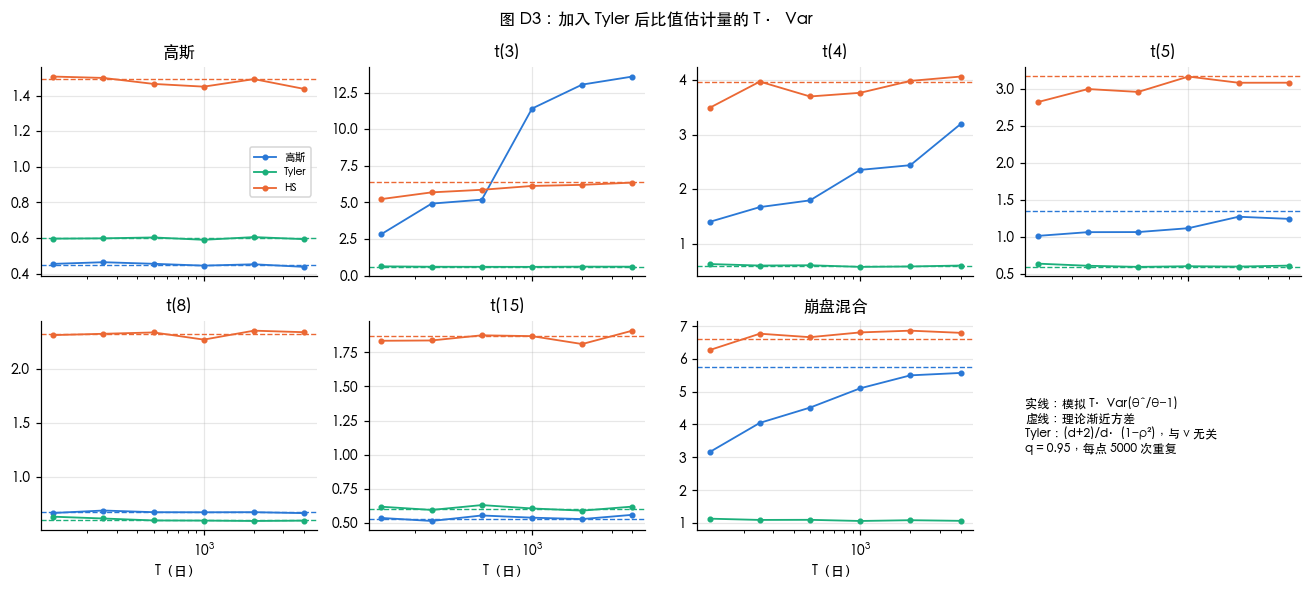

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4), sharex=True)
C_TY = "#1baf7a"
for ax, kind in zip(axes.flat, DGPS):
    for lab, c, key in [("高斯", C_GAUSS, "avar_g_rat"), ("Tyler", C_TY, None), ("HS", C_HS, "avar_hs_rat")]:
        d = SUM3[(SUM3.dgp == kind) & (SUM3.q == 0.95) & (SUM3.est == lab)]
        ax.plot(d["T"], d["Tvar"], "o-", color=c, ms=3, lw=1.2, label=lab)
        av = TH_TY.loc[(kind, 0.95), "avar_ty_rat"] if key is None else TH.loc[(kind, 0.95), key]
        if np.isfinite(av):
            ax.axhline(av, color=c, ls="--", lw=.9)
    ax.set_xscale("log")
    ax.set_title(kind)
axes.flat[0].legend(fontsize=7)
axes.flat[-1].axis("off")
axes.flat[-1].text(0, .5, "实线：模拟 T·Var(θ̂/θ−1)\n虚线：理论渐近方差\nTyler：(d+2)/d·(1−ρ²)，与 ν 无关\nq = 0.95，每点 5000 次重复", fontsize=8, va="center", transform=axes.flat[-1].transAxes)
for ax in axes[1]:
    ax.set_xlabel("T（日）")
fig.suptitle("图 D3：加入 Tyler 后比值估计量的 T · Var")
fig.tight_layout()
plt.show()

### 5.3 Tyler 与高斯插件的配对比较

同一批样本上，平方误差之差 $e_{\mathrm{Tyler}}^2-e_G^2$ 的均值（×10⁴）与 t 值；负值表示 Tyler 更好。理论预测 ν < 10 时为负。

In [20]:
rows = []
for (kind, T), g in SIM3.groupby(["dgp", "T"], sort=False):
    d = g["ty_rat_950"] ** 2 - g["g_rat_950"] ** 2
    rows.append(dict(dgp=kind, T=T, diff=d.mean() * 1e4, t=d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))))
pair = pd.DataFrame(rows)
tab9 = pair.pivot_table(index="dgp", columns="T", values=["diff", "t"]).loc[DGPS]
tab9.style.format("{:+.2f}")

### 5.4 非椭圆分布：稳健估计丢掉了尾部信息

崩盘混合下，决定 ES 的是少数大幅度的联合崩盘观测。Tyler 只看方向、对大观测降权，所以它的极限离 ES 意义下的形状更远。

In [21]:
rows = []
for q in QS:
    r = {"q": q, "高斯 渐近偏差": TH.loc[("崩盘混合", q), "abias_g_rat"] * 100,
         "Tyler 渐近偏差": TH_TY.loc[("崩盘混合", q), "abias_ty_rat"] * 100}
    d = SUM3[(SUM3.dgp == "崩盘混合") & (SUM3.q == q)].pivot_table(index="T", columns="est", values="rmse")
    for T in [250, 1000, 4000]:
        for lab in ["高斯", "Tyler", "HS"]:
            r[f"RMSE {lab} T={T}"] = d.loc[T, lab]
    rows.append(r)
tab10 = pd.DataFrame(rows).set_index("q")
tab10.T.style.format("{:.2f}")

q,0.950000,0.975000,0.990000
高斯 渐近偏差,8.90,25.10,58.67
Tyler 渐近偏差,26.61,45.43,84.46
RMSE 高斯 T=250,17.53,32.23,65.93
RMSE Tyler T=250,27.57,46.24,85.24
RMSE HS T=250,16.92,24.24,38.13
RMSE 高斯 T=1000,12.18,27.47,60.98
RMSE Tyler T=1000,26.72,45.49,84.48
RMSE HS T=1000,8.32,11.18,14.93
RMSE 高斯 T=4000,9.91,25.78,59.33
RMSE Tyler T=4000,26.57,45.37,84.37


## 6 · 结论

结论文字在运行结果之后写入 README（见「偏差–方差分解」与「Tyler 形状估计量」两节）。